In [ ]:
%load_ext autoreload
%autoreload 2

### Multi-dataset updating with PepCL for long horizon testing (and some joint updating inference)

In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT.name not in ("CLSBN26", "PepCL_Manuscript"):    
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Could not find CLSBN26 project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "Data"
SRC_DIR = PROJECT_ROOT / "src"
MODEL_CHECKPOINTS_DIR = PROJECT_ROOT / "Model_Checkpoints"
FIGURES_DIR = PROJECT_ROOT / "Figures"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR:", DATA_DIR)
print("FIGURES_DIR:", FIGURES_DIR)
print("PROJECT_ROOT in sys.path:", str(PROJECT_ROOT) in sys.path)

PROJECT_ROOT: /home/pchati/PepCL_Manuscript
DATA_DIR: /home/pchati/PepCL_Manuscript/Data
FIGURES_DIR: /home/pchati/PepCL_Manuscript/Figures
PROJECT_ROOT in sys.path: True


In [ ]:
# imports
from src.general_utils import *
from src.get_feature_data import *
from src.Model.mhcprime import *
from src.model_utils import *
from src.general_utils import *
from src.get_feature_data import *
from src.pepcl import *
from src.pepcl_multi import *
from src.mhcprime_inference import *
from src.plotting import *
from src.multi_dataset_updating_utils import *

# misc
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# change gpu
GPU_ID = 0
# GPU_ID = 1
# GPU_ID = 2
# GPU_ID = 3 # set above

torch.cuda.set_device(GPU_ID)
print(f"Using GPU: {torch.cuda.get_device_name(GPU_ID)} (ID: {torch.cuda.current_device()})")
device=f"cuda:{GPU_ID}"

Using GPU: NVIDIA H100 80GB HBM3 (ID: 0)


### Create figure directory

In [ ]:
# create figure dir
updated_figure_5_md_updating_dir=f"{FIGURES_DIR}/Revisions/Figure_5_MD_Updating"
updated_figure_5_md_updating_data_dir=f"{updated_figure_5_md_updating_dir}/Associated_Data"
os.makedirs(updated_figure_5_md_updating_dir, exist_ok=True)
os.makedirs(updated_figure_5_md_updating_data_dir, exist_ok=True)

### Get datasets

#### Format pseudosequences and get feature data

In [ ]:
# format pseudosequences
from Data.mhc_pseudo_seqs import mhc_seq_dict
mhc_seq_dict={k.removeprefix("HLA-").replace("*","").replace(":",""):v for k,v in mhc_seq_dict.items()}

In [ ]:
# get feature table and processed features
aa_features_table_ext, descriptor_groups=load_feature_data()
processed_feature_table, corr_info = process_aa_feature_table(aa_features_table_ext)
feature_names = list(processed_feature_table.columns)  # pass to FeatureProjectionEncoder

#### Get train/test sets and process

#### Load and process datasets

In [ ]:
# MS: use the ablation training set + standard validation/test sets.
ms_datasets_dir=DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_train_data=pd.read_csv(f"{ms_datasets_dir}/ms_train_data_remaining_minimal.csv",index_col=0)
ms_val_data=pd.read_csv(f"{ms_datasets_dir}/ms_val_data.csv",index_col=0)
ms_test_data=pd.read_csv(f"{ms_datasets_dir}/ms_test_data.csv",index_col=0)

In [ ]:
# YD / Holec: use the ablation train-remaining set + validation/test sets.
holec_datasets_dir=DATA_DIR / "Training_Datasets" / "Processed" / "Holec_et_al_2025"
holec_train_set=pd.read_csv(f"{holec_datasets_dir}/holec_train_set_remaining.csv",index_col=0)
holec_val_set=pd.read_csv(f"{holec_datasets_dir}/holec_val_set.csv",index_col=0)
holec_test_set=pd.read_csv(f"{holec_datasets_dir}/holec_test_set.csv",index_col=0)

In [ ]:
# EpiScan R9/RT: use both train-remaining sets and both validation/test sets.
episcan_train_test_dir=DATA_DIR / "Training_Datasets" / "Processed" / "EpiScan"
episcan_r9_train_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_r9_train_set_remaining.csv",index_col=0)
episcan_rt_train_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_rt_train_set_remaining.csv",index_col=0)
episcan_r9_val_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_r9_val_set.csv",index_col=0)
episcan_rt_val_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_rt_val_set.csv",index_col=0)
episcan_r9_test_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_r9_test_set.csv",index_col=0)
episcan_rt_test_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_rt_test_set.csv",index_col=0)
sd3_formatted=pd.read_csv(f"{episcan_train_test_dir}/sd3_formatted.csv",index_col=0)

# Preserve source before merging EpiScan R9/RT validation/test sets.
episcan_r9_val_set["dataset_source"]="r9"
episcan_rt_val_set["dataset_source"]="rt"
episcan_r9_test_set["dataset_source"]="r9"
episcan_rt_test_set["dataset_source"]="rt"


In [ ]:
# BA: pre-created multi-dataset classification train/test split.
ba_train_test_dir=DATA_DIR / "Training_Datasets" / "Processed" / "BA"
ba_train_set=pd.read_csv(f"{ba_train_test_dir}/ba_train_set_for_md_updating.csv",index_col=0)
ba_test_set=pd.read_csv(f"{ba_train_test_dir}/ba_test_set_for_md_updating.csv",index_col=0)

In [ ]:
# ESCAPE-seq: pre-created multi-dataset classification train/test split.
escape_train_test_dir=DATA_DIR / "Training_Datasets" / "Processed" / "ESCAPE_seq"
escape_train_set=pd.read_csv(f"{escape_train_test_dir}/escape_train_set_for_md_updating.csv",index_col=0)
escape_test_set=pd.read_csv(f"{escape_train_test_dir}/escape_test_set_for_md_updating.csv",index_col=0)

In [ ]:
print("Processing train, validation, and test sets...")
def processing_wrapper(df):
    df=full_process_data(df,mhc_seq_dict,remove_flank=True,add_pseudo_label=False)
    df=create_seq_allele_column(df)
    df["peptide"]=df.seq.str.replace("$","")
    df["seq_len"]=df.seq.str.replace("$","").apply(len)
    return df

ms_train_data=processing_wrapper(ms_train_data)
ms_val_data=processing_wrapper(ms_val_data)
ms_test_data=processing_wrapper(ms_test_data)

holec_train_set=processing_wrapper(holec_train_set)
holec_val_set=processing_wrapper(holec_val_set)
holec_test_set=processing_wrapper(holec_test_set)

episcan_r9_train_set=processing_wrapper(episcan_r9_train_set)
episcan_rt_train_set=processing_wrapper(episcan_rt_train_set)
episcan_r9_val_set=processing_wrapper(episcan_r9_val_set)
episcan_rt_val_set=processing_wrapper(episcan_rt_val_set)
episcan_r9_test_set=processing_wrapper(episcan_r9_test_set)
episcan_rt_test_set=processing_wrapper(episcan_rt_test_set)
sd3_formatted=processing_wrapper(sd3_formatted)

ba_train_set=processing_wrapper(ba_train_set)
ba_test_set=processing_wrapper(ba_test_set)

escape_train_set=processing_wrapper(escape_train_set)
escape_test_set=processing_wrapper(escape_test_set)
print(end="\n")

# merge episcan sets
print("Merging EpiScan R9/RT sets...")
episcan_train_set=pd.concat([episcan_r9_train_set,episcan_rt_train_set])
episcan_val_set=pd.concat([episcan_r9_val_set,episcan_rt_val_set])
episcan_test_set=pd.concat([episcan_r9_test_set,episcan_rt_test_set])
print_data_stats(episcan_train_set)
print_data_stats(episcan_val_set)
print_data_stats(episcan_test_set)
print(end="\n")

Processing train, validation, and test sets...

Merging EpiScan R9/RT sets...
Total: 2,498,576
Pos: 108,158 | 4.33%
Neg: 2,390,418 | 95.67%
N alleles: 4
Total: 33,800
Pos: 338 | 1.00%
Neg: 33,462 | 99.00%
N alleles: 4
Total: 80,000
Pos: 800 | 1.00%
Neg: 79,200 | 99.00%
N alleles: 4



In [ ]:
# aggregate sets

# Replay set is held separately to create the adaptive buffer.
train_sets={
    "ms":ms_train_data,
    "yd":holec_train_set,
    "episcan":episcan_train_set,
    "ba":ba_train_set,
    "escape":escape_train_set,
}

# BA and ESCAPE-seq intentionally have no validation sets for this classification-updating experiment.
test_sets={
    "ms_test":ms_test_data,
    "yd_test":holec_test_set,
    "episcan_test":episcan_test_set,
    "ba_test":ba_test_set,
    "escape_test":escape_test_set,
    "cov_test":sd3_formatted,
}

val_sets={
    "ms_val":ms_val_data,
    "yd_val":holec_val_set,
    "episcan_val":episcan_val_set,
}

In [ ]:
# filter, later we can keep escore and ba_value
filtered_columns=['seq','allele','label','seq_allele','n_flank','c_flank','mhc_a_1','mhc_b_1','mhc_c_1','mhc_a_2','mhc_b_2','mhc_c_2','sa_ma','mhcprime','dataset_source', 'escore', 'ba_value']
test_sets=filter_dict_columns(test_sets,filtered_columns)
val_sets=filter_dict_columns(val_sets,filtered_columns)

In [ ]:
# rekey
test_sets = {(k[:-5] if k.endswith("_test") else k): v for k, v in test_sets.items()}
val_sets = {(k.removesuffix("_val") if k.endswith("_val") else k): v for k, v in val_sets.items()}

In [ ]:
print("Cleaning train/test cross-dataset peptide-allele overlaps...")
seq_allele_overlap_matrix,train_sets=seq_allele_overlap_table(train_sets,test_sets,seq_col="seq",allele_col="allele",remove_test_from_train=True)
print(end="\n")

display(seq_allele_overlap_matrix)

# MS is used as replay buffer separately, not as an update-domain train set.
ms_train_data=train_sets["ms"].copy()
if "ms" in train_sets:
    print("Deleting MS key; used as buffer separately.")
    del train_sets["ms"]

Cleaning train/test cross-dataset peptide-allele overlaps...


Filtering train sets: 100%|██████████| 5/5 [00:50<00:00, 10.17s/it]


,ms_train,yd_train,episcan_train,ba_train,escape_train,ms_test,yd_test,episcan_test,ba_test,escape_test,cov_test
ms_train,35913223.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
yd_train,0.0,1319748.0,772.0,1298.0,0.0,0.0,0.0,55.0,194.0,0.0,7180.0
episcan_train,0.0,772.0,2498574.0,13139.0,15.0,0.0,82.0,0.0,2173.0,13.0,0.0
ba_train,0.0,1298.0,13139.0,110068.0,10.0,0.0,154.0,920.0,3.0,12.0,853.0
escape_train,0.0,0.0,15.0,10.0,23737.0,0.0,0.0,0.0,2.0,0.0,0.0
ms_test,0.0,0.0,0.0,0.0,0.0,3214300.0,0.0,0.0,0.0,0.0,0.0
yd_test,0.0,0.0,82.0,154.0,0.0,0.0,160000.0,10.0,22.0,0.0,845.0
episcan_test,0.0,55.0,0.0,920.0,0.0,0.0,10.0,80000.0,167.0,1.0,0.0
ba_test,0.0,194.0,2173.0,3.0,2.0,0.0,22.0,167.0,45211.0,2.0,219.0
escape_test,0.0,0.0,13.0,12.0,0.0,0.0,0.0,1.0,2.0,41867.0,0.0


Deleting MS key; used as buffer separately.


In [ ]:
# check to be sure
seq_allele_overlap_matrix,_=seq_allele_overlap_table(train_sets,test_sets,seq_col="seq",allele_col="allele",remove_test_from_train=True)
print(end="\n")
display(seq_allele_overlap_matrix)

Building pair sets:   0%|          | 0/10 [00:00<?, ?it/s]

Filtering train sets: 100%|██████████| 4/4 [00:03<00:00,  1.15it/s]


,yd_train,episcan_train,ba_train,escape_train,ms_test,yd_test,episcan_test,ba_test,escape_test,cov_test
yd_train,1312329.0,759.0,1232.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
episcan_train,759.0,2496307.0,13099.0,15.0,0.0,0.0,0.0,0.0,0.0,0.0
ba_train,1232.0,13099.0,108133.0,10.0,0.0,0.0,0.0,0.0,0.0,0.0
escape_train,0.0,15.0,10.0,23735.0,0.0,0.0,0.0,0.0,0.0,0.0
ms_test,0.0,0.0,0.0,0.0,3214300.0,0.0,0.0,0.0,0.0,0.0
yd_test,0.0,0.0,0.0,0.0,0.0,160000.0,10.0,22.0,0.0,845.0
episcan_test,0.0,0.0,0.0,0.0,0.0,10.0,80000.0,167.0,1.0,0.0
ba_test,0.0,0.0,0.0,0.0,0.0,22.0,167.0,45211.0,2.0,219.0
escape_test,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,41867.0,0.0
cov_test,0.0,0.0,0.0,0.0,0.0,845.0,0.0,219.0,0.0,326579.0


### Initial buffer scaling analysis

In [ ]:
# buffer scaling analysis for minimal MS base dataframe
ms_train_data_minimal=ms_train_data.copy()
ms_train_data_minimal["seq"]=ms_train_data_minimal.seq.str.replace("$", "")
ms_train_data_minimal=ms_train_data_minimal[["seq", "allele", "label"]]

train_sets_minimal={}
for df_name, df in train_sets.items():
    df_f=df.copy()
    df_f["seq"]=df_f.seq.str.replace("$", "")
    df_f=df_f[["seq", "allele", "label"]]
    train_sets_minimal[df_name]=df_f

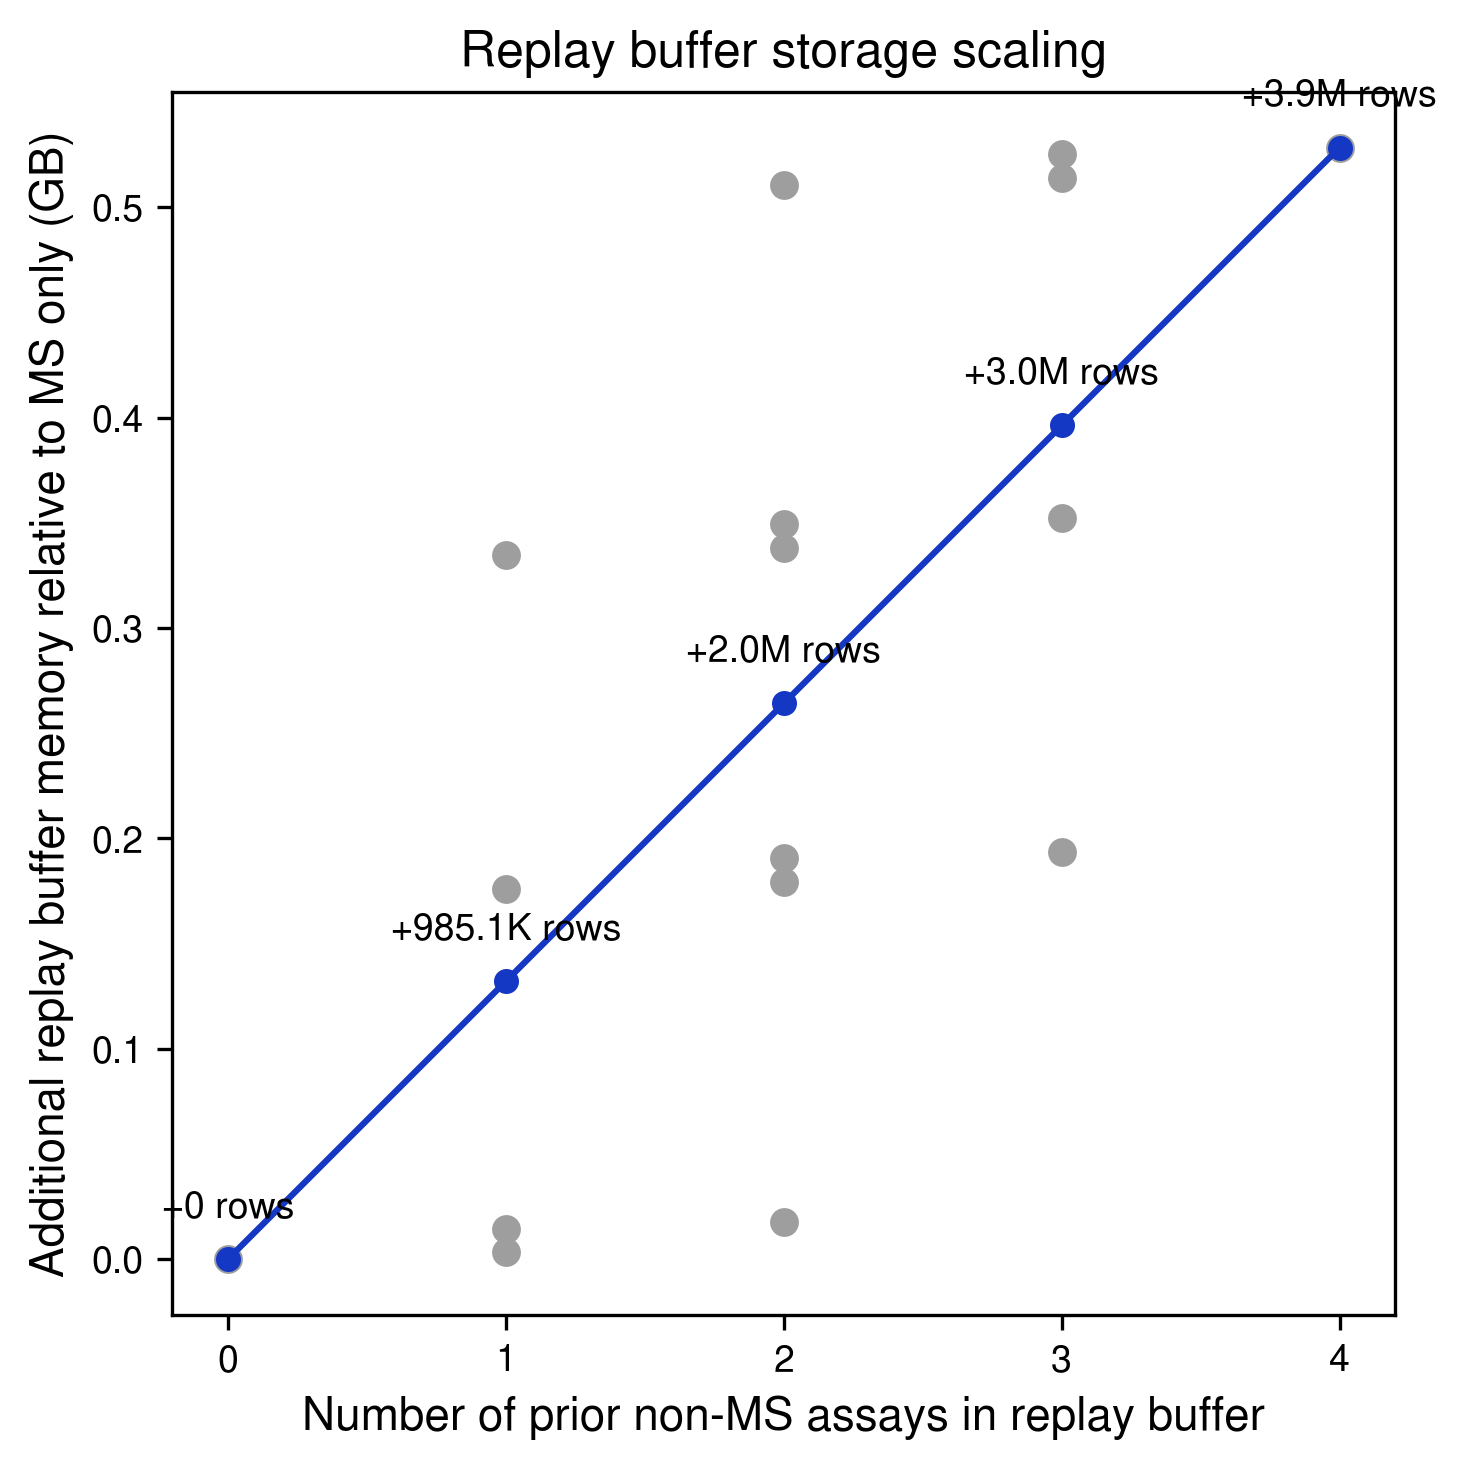

CPU times: user 11.8 s, sys: 1.22 s, total: 13 s
Wall time: 12.7 s


In [ ]:
%%time

buffer_scaling_df,fig,ax=summarize_replay_buffer_scaling(
    ms_train_data=ms_train_data_minimal,
    train_sets=train_sets_minimal,
    memory_only=True,
    point_color="#9e9e9e",
    mean_color="#1437c4",
    annotate_row_increase=True,
    annotation_format="compact",
    memory_only_fig_size=(5,5),
    dpi=300,
    # save_path=f"{updated_figure_5_md_updating_dir}/replay_buffer_scaling",
)

In [ ]:
# save for figure generation
train_sets_minimal_w_ms=train_sets_minimal.copy()
train_sets_minimal_w_ms["ms"]=ms_train_data_minimal
os.makedirs(f"{DATA_DIR}/Multi_Dataset_Updating_Results/Other_Results/", exist_ok=True)
# save_dict_pickle(train_sets_minimal_w_ms, f"{DATA_DIR}/Multi_Dataset_Updating_Results/Other_Results/train_sets_minimal_w_ms.pkl")

#### Split into allele-specific sets

In [ ]:
%%time
# get allele-specific partitions for each dataset
partition_counts={
    "yd": 4,
    "episcan": 4,
    "ba": 4,
    "escape": 4,
}
train_sets_allele_partitions, train_sets_allele_partitions_summary=partition_datasets_by_allele(train_sets, partition_counts, allele_col="allele", label_col="label", seed=42)

Partitioning datasets:   0%|          | 0/4 [00:00<?, ?it/s]

Partitioning datasets: 100%|██████████| 4/4 [00:02<00:00,  1.69it/s]

CPU times: user 1.94 s, sys: 461 ms, total: 2.4 s
Wall time: 2.39 s


In [ ]:
print(train_sets_allele_partitions_summary)
print(train_sets_allele_partitions.keys())

{'yd_1': {'alleles': ['A3002', 'C1202', 'B5801', 'B5502'], 'n_alleles': 4, 'n_total': 327947, 'n_pos': 7281, 'n_neg': 320666}, 'episcan_1': {'alleles': ['B5701'], 'n_alleles': 1, 'n_total': 614198, 'n_pos': 11244, 'n_neg': 602954}, 'ba_1': {'alleles': ['A0101', 'B1402', 'B8101', 'B4002', 'B5401', 'A2902', 'B3901', 'A6901', 'C1402', 'A7401', 'A0202', 'A6601', 'C1502', 'A6801', 'A3101', 'A0206', 'A0211', 'B3906', 'B5301', 'A0204', 'B5802'], 'n_alleles': 21, 'n_total': 26785, 'n_pos': 11025, 'n_neg': 15760}, 'escape_1': {'alleles': ['B2705', 'A3101', 'A0301', 'B5701', 'C0401', 'B5201', 'B1502', 'C0702', 'B1503', 'B4006', 'B5401'], 'n_alleles': 11, 'n_total': 5401, 'n_pos': 1360, 'n_neg': 4041}, 'yd_2': {'alleles': ['B3901', 'A1101', 'A0101', 'B3502'], 'n_alleles': 4, 'n_total': 328940, 'n_pos': 6705, 'n_neg': 322235}, 'episcan_2': {'alleles': ['A0201'], 'n_alleles': 1, 'n_total': 627450, 'n_pos': 25598, 'n_neg': 601852}, 'ba_2': {'alleles': ['A1102', 'B1517', 'C0602', 'B3801', 'A0207', 'B

### Load base MHCPrime

In [ ]:
# ============================================================
# LOAD MHCPrime BASE FOR ABLATIONS
# ============================================================
print("Loading MHCPrime base checkpoint...")
tokenizer=AminoAcidTokenizer()

base_model_params={
    'vocab_size':tokenizer.vocab_size,
    'embed_dim':480,
    'fc_hidden_dims':[240,120],
    'fc_dropout':0.1,
    'n_heads':16,
    'max_peptide_len':34,
    'max_mhc_len':34,
    "n_peptide_layers":2,
    "n_mhc_layers":1,
    'n_concat_layers':3,
    'add_pos_enc':True,
    'use_segment_embedder':True,
    'dim_feedforward_multiplier':1,
    'debugging':False,
    'fc_output_dim':1,
    'pooling':'cls',
    "ffnn_use_layernorm":False,
    'use_feature_table':True,
    "feature_table":processed_feature_table,
    "sequence_embedder_feature_names":feature_names,
    'sequence_embedder_feature_mode':"concat",
    'sequence_embedder_tokenizer':tokenizer,
    "peptide_start_pos":1,
    "mhc_start_pos":35,
    "pos_enc_type":"sincos",
    "seed":42,
    "add_peptide_conformer":True,
    "peptide_conformer_num_layers":2,
    "peptide_conformer_n_heads":16,
    "peptide_conformer_conv_kernel":5,
    "peptide_conformer_dropout":0.0,
    "add_mhc_conformer":False,
    "mhc_conformer_num_layers":2,
    "mhc_conformer_n_heads":16,
    "mhc_conformer_conv_kernel":5,
    "mhc_conformer_dropout":0.0,
    "add_fusion_conformer":True,
    "fusion_conformer_num_layers":1,
    "fusion_conformer_n_heads":16,
    "fusion_conformer_conv_kernel":7,
    "fusion_conformer_dropout":0.0,
    "fusion_conformer_mask_bos":True,
    "ff_pre_post_swiglu":False,
    "legacy_init_compat":True,
}

base_model_dir=MODEL_CHECKPOINTS_DIR / "MHCPrime_Base_for_Ablations" / "Checkpoints"
ckpt_path=base_model_dir / "model_final.pt"
device=torch.device(f"cuda:{GPU_ID}" if torch.cuda.is_available() else "cpu")

clear_all_gpu_memory()
mhcprime=init_model(base_model_params,print_check=False,print_params=True)
state_dict=torch.load(ckpt_path,map_location="cpu")
mhcprime.load_state_dict(state_dict,strict=True)
mhcprime.to(device); mhcprime.eval()
print("Model loaded from checkpoint...")
print(f"Checkpoint: {ckpt_path}")
print(f"Model device: {next(mhcprime.parameters()).device}\n")

Loading MHCPrime base checkpoint...
All GPU memory has been cleared.
Current GPU memory allocated: 0.00 GB
Current GPU memory reserved: 0.00 GB
[FeatureProjectionEncoder] Warning: no features found for tokens: ['$', '*', '<BOS>']
Number of trainable modules: 202
Number of trainable parameters: 25751991
Model loaded successfully...
Model loaded from checkpoint...
Checkpoint: /home/pchati/PepCL_Manuscript/Model_Checkpoints/MHCPrime_Base_for_Ablations/Checkpoints/model_final.pt
Model device: cuda:0



### Inference for joint updating models

In [ ]:
%%time
# joint models
model_save_root=MODEL_CHECKPOINTS_DIR / "All_Dataset_Joint_Updating"

joint_retraining_models={}

for model_file in os.listdir(model_save_root):
    model_name = model_file.removesuffix(".pt")
    print(model_name)
    ckpt_path=f"{model_save_root}/{model_file}"
    model=init_model(base_model_params,print_check=False,print_params=True)
    state_dict=torch.load(ckpt_path,map_location="cpu")
    model.load_state_dict(state_dict,strict=True)
    model.to(device); model.eval()
    print("Model loaded from checkpoint...")
    print(f"Checkpoint: {ckpt_path}")
    print(f"Model device: {next(model.parameters()).device}\n")
    joint_retraining_models[model_name]=model

model_ft_multi_v2_merged_300step_seed_2
[FeatureProjectionEncoder] Warning: no features found for tokens: ['$', '*', '<BOS>']
Number of trainable modules: 202
Number of trainable parameters: 25751991
Model loaded successfully...
Model loaded from checkpoint...
Checkpoint: /home/pchati/PepCL_Manuscript/Model_Checkpoints/All_Dataset_Joint_Updating/model_ft_multi_v2_merged_300step_seed_2.pt
Model device: cuda:0

model_pepcl_multi_v2_1200step_seed_3
[FeatureProjectionEncoder] Warning: no features found for tokens: ['$', '*', '<BOS>']
Number of trainable modules: 202
Number of trainable parameters: 25751991
Model loaded successfully...
Model loaded from checkpoint...
Checkpoint: /home/pchati/PepCL_Manuscript/Model_Checkpoints/All_Dataset_Joint_Updating/model_pepcl_multi_v2_1200step_seed_3.pt
Model device: cuda:0

model_pepcl_multi_v2_1200step_seed_1
[FeatureProjectionEncoder] Warning: no features found for tokens: ['$', '*', '<BOS>']
Number of trainable modules: 202
Number of trainable para

In [ ]:
%%time
base_model=copy.deepcopy(mhcprime)
joint_retraining_models["mhcprime_abt"]=base_model

for df_name, df in test_sets.items():
    build_caches=True
    if build_caches:
        data_to_run_path=f"{DATA_DIR}/dataset_cache.pt"

        build_token_cache(df, data_to_run_path, tokenizer, use_domain_id=False)

    data_to_run_path=f"{DATA_DIR}/dataset_cache.pt"
    for model_name, model in joint_retraining_models.items():
        model.eval()
        with torch.no_grad():
            output_scores=run_mhcprime_fast(model, data_to_run_path, batch_size=3072, num_workers=16, compile_model=False, use_domain_id=False)

        df[model_name]=output_scores.detach().cpu().tolist()

    # delete dataset cache
    data_to_run_path=f"{DATA_DIR}/dataset_cache.pt"
    os.remove(data_to_run_path)

    test_sets[df_name]=df

In [ ]:
# save results
full_output_root=DATA_DIR / "Multi_Dataset_Updating_Results" / "All_Dataset_Joint_Updating"
# save_dict_pickle(test_sets, f"{full_output_root}/test_sets_joint_updating.pkl")

### Allele partition long horizon updating

#### Run PepCL

In [ ]:
num_workers=4
pepcl_multi_base_params=dict(
    tokenizer=tokenizer,
    device="cuda",
    steps=300,
    output_dir=None,
    save_every_n_steps=2000,
    seed=42,
    num_workers=num_workers,
    collate_fn=collate_fn,
    num_ms_pos=2000,
    num_nonms_pos=2000,
    ms_neg_ratio=1.0,
    nonms_neg_ratio=1.0,
    auto_calibrate=True,
    calibration_steps=1,
    ms_batch_size=3072,
    nonms_batch_size=3072,
    encoder_lr=2e-4,
    decoder_lr=2e-4,
    weight_decay=0.01,
    warmup_ratio=0.1,
    update_domain_embeddings=False,
    primary_task_id=1,
    sequential_backprop=True,
    ms_loss_type="logsmoothap",
    ms_loss_alpha=10.0,
    ms_lambda=1.0,
    nonms_loss_type="logsmoothap",
    nonms_loss_alpha=10.0,
    ft_lambda=1.0,
    dr_lambda=1e-5,
    dr_loss_type="mse",
)


In [ ]:
%%time
"""
PepCL adaptive buffer

NOTE: make sure the correct train set is used.
"""
model_pepcl_multi_r_dr=copy.deepcopy(mhcprime)

pepcl_multi_r_dr_models={}

current_base_params=pepcl_multi_base_params.copy()
current_base_params["seed"]=0

task_order_name="t1_allele_partition"

task_order=list(train_sets_allele_partitions.keys())
print("Task order: ", task_order)

temp_ms_train_data=ms_train_data.copy()
temp_ms_train_data["domain_id"]=0
temp_train_data=temp_ms_train_data.copy()

for domain_id,ft_train_set_name in enumerate(task_order,start=1):
    print(f"\n--- Stage s{domain_id}: {ft_train_set_name} ---")

    temp_ft_train_set_df=train_sets_allele_partitions[ft_train_set_name].copy()
    temp_ft_train_set_df["domain_id"]=domain_id
    temp_train_data=pd.concat([temp_train_data,temp_ft_train_set_df],ignore_index=True)
    temp_train_data.reset_index(inplace=True,drop=True)
    print_data_stats(temp_train_data)

    replay_domain_ids=list(range(domain_id))
    update_domain_id=domain_id
    print(f"Replay domains: {replay_domain_ids}")
    print(f"Update domain: {update_domain_id}")

    # =====================================================
    # PepCL Multi: equal replay representation, replay + DR
    # =====================================================
    print("PepCL Multi w/ Replay and DR")
    replay_dr_params=current_base_params.copy(); replay_dr_params["dr_lambda"]=1e-5
    pepcl=PepCL_Multi(
        model=model_pepcl_multi_r_dr,train_df=temp_train_data,use_replay=True,
        replay_domain_ids=replay_domain_ids,update_domain_id=update_domain_id,
        ms_replay_fraction="equal",**replay_dr_params,
    )
    training_stats=pepcl.train()


    pepcl_multi_r_dr_model_name=f"{task_order_name}_s{domain_id}_pepcl_multi_replay_dr_full_buffer"

    pepcl_multi_r_dr_models[pepcl_multi_r_dr_model_name]=copy.deepcopy(model_pepcl_multi_r_dr)

    print(pepcl_multi_r_dr_model_name,id(pepcl_multi_r_dr_models[pepcl_multi_r_dr_model_name]))


Task order:  ['yd_1', 'episcan_1', 'ba_1', 'escape_1', 'yd_2', 'episcan_2', 'ba_2', 'escape_2', 'yd_3', 'episcan_3', 'ba_3', 'escape_3', 'yd_4', 'episcan_4', 'ba_4', 'escape_4']

--- Stage s1: yd_1 ---
Total: 36,241,170
Pos: 731,401 | 2.02%
Neg: 35,509,769 | 97.98%
N alleles: 192
Replay domains: [0]
Update domain: 1
PepCL Multi w/ Replay and DR
[PepCL_Multi] Replay batch allocation:
  MS: 3072 / 3072

[PepCL_Multi] Auto-calibrated sampling:
  Replay MS (domain 0): batch=3072, alleles=192, A_eff=40.70, balance=0.212, target_pos/cycle=1536, q_pos median=4.0 [1, 96], reuse median=0.0027, reuse max=1.0000, neg_ratio=1.0
  FT domain 1: batch=3072, alleles=4, A_eff=3.76, balance=0.940, target_pos/cycle=1536, q_pos median=383.0 [377, 393], reuse median=0.2181, reuse max=0.3038, neg_ratio=1.0



PepCL_Multi: 100%|██████████| 300/300 [03:56<00:00,  1.27it/s, Replay=0.005848, FT=0.000195, DR=0.002711]


t1_allele_partition_s1_pepcl_multi_replay_dr_full_buffer 140027609865232

--- Stage s2: episcan_1 ---
Total: 36,855,368
Pos: 742,645 | 2.02%
Neg: 36,112,723 | 97.98%
N alleles: 192
Replay domains: [0, 1]
Update domain: 2
PepCL Multi w/ Replay and DR
[PepCL_Multi] Replay batch allocation:
  MS: 1536 / 3072
  domain 1: 1536 / 3072

[PepCL_Multi] Auto-calibrated sampling:
  Replay MS (domain 0): batch=1536, alleles=192, A_eff=40.70, balance=0.212, target_pos/cycle=768, q_pos median=2.0 [1, 48], reuse median=0.0013, reuse max=1.0000, neg_ratio=1.0
  Replay domain 1: batch=1536, alleles=4, A_eff=3.76, balance=0.940, target_pos/cycle=768, q_pos median=191.5 [188, 197], reuse median=0.1090, reuse max=0.1515, neg_ratio=1.0
  FT domain 2: batch=3072, alleles=1, A_eff=1.00, balance=1.000, target_pos/cycle=1536, q_pos median=1536.0 [1536, 1536], reuse median=0.1366, reuse max=0.1366, neg_ratio=1.0



PepCL_Multi: 100%|██████████| 300/300 [03:56<00:00,  1.27it/s, Replay=0.004844, FT=0.003693, DR=0.002579]


t1_allele_partition_s2_pepcl_multi_replay_dr_full_buffer 140027609968112

--- Stage s3: ba_1 ---
Total: 36,882,153
Pos: 753,670 | 2.04%
Neg: 36,128,483 | 97.96%
N alleles: 192
Replay domains: [0, 1, 2]
Update domain: 3
PepCL Multi w/ Replay and DR
[PepCL_Multi] Replay batch allocation:
  MS: 1024 / 3072
  domain 1: 1024 / 3072
  domain 2: 1024 / 3072

[PepCL_Multi] Auto-calibrated sampling:
  Replay MS (domain 0): batch=1024, alleles=192, A_eff=40.70, balance=0.212, target_pos/cycle=512, q_pos median=2.0 [1, 32], reuse median=0.0008, reuse max=0.1667, neg_ratio=1.0
  Replay domain 1: batch=1024, alleles=4, A_eff=3.76, balance=0.940, target_pos/cycle=512, q_pos median=127.5 [126, 131], reuse median=0.0726, reuse max=0.1015, neg_ratio=1.0
  Replay domain 2: batch=1024, alleles=1, A_eff=1.00, balance=1.000, target_pos/cycle=512, q_pos median=512.0 [512, 512], reuse median=0.0455, reuse max=0.0455, neg_ratio=1.0
  FT domain 3: batch=3072, alleles=20, A_eff=7.93, balance=0.396, target_pos/c

...

t1_allele_partition_s14_pepcl_multi_replay_dr_full_buffer 140028031534272

--- Stage s15: ba_4 ---
Total: 39,847,333
Pos: 901,716 | 2.26%
Neg: 38,945,617 | 97.74%
N alleles: 192
Replay domains: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
Update domain: 15
PepCL Multi w/ Replay and DR
[PepCL_Multi] Replay batch allocation:
  MS: 205 / 3072
  domain 1: 205 / 3072
  domain 2: 205 / 3072
  domain 3: 205 / 3072
  domain 4: 205 / 3072
  domain 5: 205 / 3072
  domain 6: 205 / 3072
  domain 7: 205 / 3072
  domain 8: 205 / 3072
  domain 9: 205 / 3072
  domain 10: 205 / 3072
  domain 11: 205 / 3072
  domain 12: 204 / 3072
  domain 13: 204 / 3072
  domain 14: 204 / 3072

[PepCL_Multi] Auto-calibrated sampling:
  Replay MS (domain 0): batch=205, alleles=192, A_eff=40.70, balance=0.212, target_pos/cycle=102, q_pos median=1.0 [1, 6], reuse median=0.0002, reuse max=0.0004, neg_ratio=1.0
  Replay domain 1: batch=205, alleles=4, A_eff=3.76, balance=0.940, target_pos/cycle=102, q_pos median=25.5 

PepCL_Multi: 100%|██████████| 300/300 [03:57<00:00,  1.27it/s, Replay=0.002813, FT=0.000010, DR=0.000239] 


t1_allele_partition_s15_pepcl_multi_replay_dr_full_buffer 140027607588240

--- Stage s16: escape_4 ---
Total: 39,853,733
Pos: 903,530 | 2.27%
Neg: 38,950,203 | 97.73%
N alleles: 192
Replay domains: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
Update domain: 16
PepCL Multi w/ Replay and DR
[PepCL_Multi] Replay batch allocation:
  MS: 192 / 3072
  domain 1: 192 / 3072
  domain 2: 192 / 3072
  domain 3: 192 / 3072
  domain 4: 192 / 3072
  domain 5: 192 / 3072
  domain 6: 192 / 3072
  domain 7: 192 / 3072
  domain 8: 192 / 3072
  domain 9: 192 / 3072
  domain 10: 192 / 3072
  domain 11: 192 / 3072
  domain 12: 192 / 3072
  domain 13: 192 / 3072
  domain 14: 192 / 3072
  domain 15: 192 / 3072

[PepCL_Multi] Auto-calibrated sampling:
  Replay MS (domain 0): batch=192, alleles=192, A_eff=40.70, balance=0.212, target_pos/cycle=96, q_pos median=1.0 [1, 6], reuse median=0.0002, reuse max=0.0004, neg_ratio=1.0
  Replay domain 1: batch=192, alleles=4, A_eff=3.76, balance=0.940, target_po

PepCL_Multi: 100%|██████████| 300/300 [03:57<00:00,  1.26it/s, Replay=0.002588, FT=0.000006, DR=0.000169] 


t1_allele_partition_s16_pepcl_multi_replay_dr_full_buffer 139998283451360
CPU times: user 1h 16min 54s, sys: 11min 14s, total: 1h 28min 9s
Wall time: 1h 27min 27s


In [ ]:
# save models

# save_models=True
save_models=False

t1_allele_partition_pepcl_r_dr_fb_dir=f"{MODEL_CHECKPOINTS_DIR}/t1_allele_partition_models/pepcl_multi_replay_dr_full_buffer"
os.makedirs(t1_allele_partition_pepcl_r_dr_fb_dir, exist_ok=True)

if save_models:
    for model_name, model in pepcl_multi_r_dr_models.items():
        print(model_name)
        torch.save(model.state_dict(), f"{t1_allele_partition_pepcl_r_dr_fb_dir}/{model_name}.pt")

t1_allele_partition_s1_pepcl_multi_replay_dr_full_buffer
t1_allele_partition_s2_pepcl_multi_replay_dr_full_buffer
t1_allele_partition_s3_pepcl_multi_replay_dr_full_buffer
t1_allele_partition_s4_pepcl_multi_replay_dr_full_buffer
t1_allele_partition_s5_pepcl_multi_replay_dr_full_buffer
t1_allele_partition_s6_pepcl_multi_replay_dr_full_buffer
t1_allele_partition_s7_pepcl_multi_replay_dr_full_buffer
t1_allele_partition_s8_pepcl_multi_replay_dr_full_buffer
t1_allele_partition_s9_pepcl_multi_replay_dr_full_buffer
t1_allele_partition_s10_pepcl_multi_replay_dr_full_buffer
t1_allele_partition_s11_pepcl_multi_replay_dr_full_buffer
t1_allele_partition_s12_pepcl_multi_replay_dr_full_buffer
t1_allele_partition_s13_pepcl_multi_replay_dr_full_buffer
t1_allele_partition_s14_pepcl_multi_replay_dr_full_buffer
t1_allele_partition_s15_pepcl_multi_replay_dr_full_buffer
t1_allele_partition_s16_pepcl_multi_replay_dr_full_buffer


In [ ]:
%%time
"""
PepCL adaptive buffer; fixed 50% MS in replay

NOTE: make sure the correct train set is used.
"""
model_pepcl_multi_r_dr_50pct_ms=copy.deepcopy(mhcprime)

pepcl_multi_r_dr_50pct_ms_models={}

current_base_params=pepcl_multi_base_params.copy()
current_base_params["seed"]=0

task_order_name="t1_allele_partition"

task_order=list(train_sets_allele_partitions.keys())
print("Task order: ", task_order)

temp_ms_train_data=ms_train_data.copy()
temp_ms_train_data["domain_id"]=0
temp_train_data=temp_ms_train_data.copy()

for domain_id, ft_train_set_name in enumerate(tqdm(task_order, desc="Tasks"), start=1):
    print(f"\n--- Stage s{domain_id}: {ft_train_set_name} ---")

    temp_ft_train_set_df=train_sets_allele_partitions[ft_train_set_name].copy()
    temp_ft_train_set_df["domain_id"]=domain_id
    temp_train_data=pd.concat([temp_train_data,temp_ft_train_set_df],ignore_index=True)
    temp_train_data.reset_index(inplace=True,drop=True)
    print_data_stats(temp_train_data)

    replay_domain_ids=list(range(domain_id))
    update_domain_id=domain_id
    print(f"Replay domains: {replay_domain_ids}")
    print(f"Update domain: {update_domain_id}")

    # =====================================================
    # PepCL Multi: fixed 50% MS replay, replay + DR
    # =====================================================
    print("PepCL Multi w/ Replay and DR, 50% MS replay")
    replay_dr_50pct_ms_params=current_base_params.copy(); replay_dr_50pct_ms_params["dr_lambda"]=1e-5
    pepcl=PepCL_Multi(
        model=model_pepcl_multi_r_dr_50pct_ms,train_df=temp_train_data,use_replay=True,
        replay_domain_ids=replay_domain_ids,update_domain_id=update_domain_id,
        ms_replay_fraction=0.5,**replay_dr_50pct_ms_params,
    )
    training_stats=pepcl.train()

    pepcl_multi_r_dr_50pct_ms_model_name=f"{task_order_name}_s{domain_id}_pepcl_multi_replay_dr_full_buffer_50pct_ms"

    pepcl_multi_r_dr_50pct_ms_models[pepcl_multi_r_dr_50pct_ms_model_name]=copy.deepcopy(model_pepcl_multi_r_dr_50pct_ms)

    print(pepcl_multi_r_dr_50pct_ms_model_name,id(pepcl_multi_r_dr_50pct_ms_models[pepcl_multi_r_dr_50pct_ms_model_name]))


Task order:  ['yd_1', 'episcan_1', 'ba_1', 'escape_1', 'yd_2', 'episcan_2', 'ba_2', 'escape_2', 'yd_3', 'episcan_3', 'ba_3', 'escape_3', 'yd_4', 'episcan_4', 'ba_4', 'escape_4']


Tasks:   0%|          | 0/16 [00:00<?, ?it/s]


--- Stage s1: yd_1 ---
Total: 36,241,170
Pos: 731,401 | 2.02%
Neg: 35,509,769 | 97.98%
N alleles: 192
Replay domains: [0]
Update domain: 1
PepCL Multi w/ Replay and DR, 50% MS replay
[PepCL_Multi] Replay batch allocation:
  MS: 3072 / 3072

[PepCL_Multi] Auto-calibrated sampling:
  Replay MS (domain 0): batch=3072, alleles=192, A_eff=40.70, balance=0.212, target_pos/cycle=1536, q_pos median=4.0 [1, 96], reuse median=0.0027, reuse max=1.0000, neg_ratio=1.0
  FT domain 1: batch=3072, alleles=4, A_eff=3.76, balance=0.940, target_pos/cycle=1536, q_pos median=383.0 [377, 393], reuse median=0.2181, reuse max=0.3038, neg_ratio=1.0



Tasks:   6%|▋         | 1/16 [04:55<1:13:47, 295.18s/it]

t1_allele_partition_s1_pepcl_multi_replay_dr_full_buffer_50pct_ms 140413395733760

--- Stage s2: episcan_1 ---
Total: 36,855,368
Pos: 742,645 | 2.02%
Neg: 36,112,723 | 97.98%
N alleles: 192
Replay domains: [0, 1]
Update domain: 2
PepCL Multi w/ Replay and DR, 50% MS replay
[PepCL_Multi] Replay batch allocation:
  MS: 1536 / 3072
  domain 1: 1536 / 3072

[PepCL_Multi] Auto-calibrated sampling:
  Replay MS (domain 0): batch=1536, alleles=192, A_eff=40.70, balance=0.212, target_pos/cycle=768, q_pos median=2.0 [1, 48], reuse median=0.0013, reuse max=1.0000, neg_ratio=1.0
  Replay domain 1: batch=1536, alleles=4, A_eff=3.76, balance=0.940, target_pos/cycle=768, q_pos median=191.5 [188, 197], reuse median=0.1090, reuse max=0.1515, neg_ratio=1.0
  FT domain 2: batch=3072, alleles=1, A_eff=1.00, balance=1.000, target_pos/cycle=1536, q_pos median=1536.0 [1536, 1536], reuse median=0.1366, reuse max=0.1366, neg_ratio=1.0



...

t1_allele_partition_s14_pepcl_multi_replay_dr_full_buffer_50pct_ms 140413398455680

--- Stage s15: ba_4 ---
Total: 39,847,333
Pos: 901,716 | 2.26%
Neg: 38,945,617 | 97.74%
N alleles: 192
Replay domains: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
Update domain: 15
PepCL Multi w/ Replay and DR, 50% MS replay
[PepCL_Multi] Replay batch allocation:
  MS: 1536 / 3072
  domain 1: 110 / 3072
  domain 2: 110 / 3072
  domain 3: 110 / 3072
  domain 4: 110 / 3072
  domain 5: 110 / 3072
  domain 6: 110 / 3072
  domain 7: 110 / 3072
  domain 8: 110 / 3072
  domain 9: 110 / 3072
  domain 10: 110 / 3072
  domain 11: 109 / 3072
  domain 12: 109 / 3072
  domain 13: 109 / 3072
  domain 14: 109 / 3072

[PepCL_Multi] Auto-calibrated sampling:
  Replay MS (domain 0): batch=1536, alleles=192, A_eff=40.70, balance=0.212, target_pos/cycle=768, q_pos median=2.0 [1, 48], reuse median=0.0013, reuse max=1.0000, neg_ratio=1.0
  Replay domain 1: batch=110, alleles=4, A_eff=3.76, balance=0.940, target_pos/cy

Tasks:  94%|█████████▍| 15/16 [1:21:00<05:32, 332.86s/it]

t1_allele_partition_s15_pepcl_multi_replay_dr_full_buffer_50pct_ms 140404768630528

--- Stage s16: escape_4 ---
Total: 39,853,733
Pos: 903,530 | 2.27%
Neg: 38,950,203 | 97.73%
N alleles: 192
Replay domains: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
Update domain: 16
PepCL Multi w/ Replay and DR, 50% MS replay
[PepCL_Multi] Replay batch allocation:
  MS: 1536 / 3072
  domain 1: 103 / 3072
  domain 2: 103 / 3072
  domain 3: 103 / 3072
  domain 4: 103 / 3072
  domain 5: 103 / 3072
  domain 6: 103 / 3072
  domain 7: 102 / 3072
  domain 8: 102 / 3072
  domain 9: 102 / 3072
  domain 10: 102 / 3072
  domain 11: 102 / 3072
  domain 12: 102 / 3072
  domain 13: 102 / 3072
  domain 14: 102 / 3072
  domain 15: 102 / 3072

[PepCL_Multi] Auto-calibrated sampling:
  Replay MS (domain 0): batch=1536, alleles=192, A_eff=40.70, balance=0.212, target_pos/cycle=768, q_pos median=2.0 [1, 48], reuse median=0.0013, reuse max=1.0000, neg_ratio=1.0
  Replay domain 1: batch=103, alleles=4, A_eff=3.

Tasks: 100%|██████████| 16/16 [1:26:37<00:00, 324.82s/it]

t1_allele_partition_s16_pepcl_multi_replay_dr_full_buffer_50pct_ms 140384639663120
CPU times: user 1h 17min 23s, sys: 10min 20s, total: 1h 27min 44s
Wall time: 1h 26min 48s


In [ ]:
# save models

# save_models=True
save_models=False

t1_allele_partition_pepcl_r_dr_fb_50pct_ms_dir=f"{MODEL_CHECKPOINTS_DIR}/t1_allele_partition_models/pepcl_multi_replay_dr_full_buffer_50pct_ms"
os.makedirs(t1_allele_partition_pepcl_r_dr_fb_50pct_ms_dir, exist_ok=True)

if save_models:
    for model_name, model in pepcl_multi_r_dr_50pct_ms_models.items():
        print(model_name)
        torch.save(model.state_dict(), f"{t1_allele_partition_pepcl_r_dr_fb_50pct_ms_dir}/{model_name}.pt")

t1_allele_partition_s1_pepcl_multi_replay_dr_full_buffer_50pct_ms
t1_allele_partition_s2_pepcl_multi_replay_dr_full_buffer_50pct_ms
t1_allele_partition_s3_pepcl_multi_replay_dr_full_buffer_50pct_ms
t1_allele_partition_s4_pepcl_multi_replay_dr_full_buffer_50pct_ms
t1_allele_partition_s5_pepcl_multi_replay_dr_full_buffer_50pct_ms
t1_allele_partition_s6_pepcl_multi_replay_dr_full_buffer_50pct_ms
t1_allele_partition_s7_pepcl_multi_replay_dr_full_buffer_50pct_ms
t1_allele_partition_s8_pepcl_multi_replay_dr_full_buffer_50pct_ms
t1_allele_partition_s9_pepcl_multi_replay_dr_full_buffer_50pct_ms
t1_allele_partition_s10_pepcl_multi_replay_dr_full_buffer_50pct_ms
t1_allele_partition_s11_pepcl_multi_replay_dr_full_buffer_50pct_ms
t1_allele_partition_s12_pepcl_multi_replay_dr_full_buffer_50pct_ms
t1_allele_partition_s13_pepcl_multi_replay_dr_full_buffer_50pct_ms
t1_allele_partition_s14_pepcl_multi_replay_dr_full_buffer_50pct_ms
t1_allele_partition_s15_pepcl_multi_replay_dr_full_buffer_50pct_ms
t1_a

#### Analysis

In [ ]:
%%time
# load allele partitions across seeds for long horizon updating
train_sets_allele_partitions_across_seeds={
    0: train_sets_allele_partitions,
}

seeds=[1,2,3,4]
for pepcl_seed in tqdm(seeds):
   train_sets_allele_partitions_seed=load_dict_pickle(f"{DATA_DIR}/Multi_Dataset_Updating_Results/T1_Allele_Partition_Sets/train_sets_allele_partitions_seed_{pepcl_seed}.pkl")
   train_sets_allele_partitions_across_seeds[pepcl_seed]=train_sets_allele_partitions_seed

 50%|█████     | 2/4 [00:04<00:04,  2.38s/it]

100%|██████████| 4/4 [00:08<00:00,  2.03s/it]

CPU times: user 5.45 s, sys: 2.35 s, total: 7.79 s
Wall time: 8.14 s


In [ ]:
%%time
# load inference results across seeds for long horizon updating
test_sets_seed_0=load_dict_pickle(f"{DATA_DIR}/Multi_Dataset_Updating_Results/T1_Allele_Partition_Sets/Results/test_sets_allele_partitions_seed_0.pkl")
test_sets_seed_12=load_dict_pickle(f"{DATA_DIR}/Multi_Dataset_Updating_Results/T1_Allele_Partition_Sets/Results/test_sets_allele_partitions_seed_12.pkl")
test_sets_seed_34=load_dict_pickle(f"{DATA_DIR}/Multi_Dataset_Updating_Results/T1_Allele_Partition_Sets/Results/test_sets_allele_partitions_seed_34.pkl")

test_sets_seed_0 = {(k[:-5] if k.endswith("_test") else k): v for k, v in test_sets_seed_0.items()}
test_sets_seed_12 = {(k[:-5] if k.endswith("_test") else k): v for k, v in test_sets_seed_12.items()}
test_sets_seed_34 = {(k[:-5] if k.endswith("_test") else k): v for k, v in test_sets_seed_34.items()}

CPU times: user 3.57 s, sys: 2.05 s, total: 5.62 s
Wall time: 5.62 s


In [ ]:
# merge dicts
test_sets_multi_seed=merge_two_dicts_by_keys(test_sets_seed_0, test_sets_seed_12, ['ms', 'yd', 'episcan', 'ba', 'escape', 'cov'])
test_sets_multi_seed=merge_two_dicts_by_keys(test_sets_multi_seed, test_sets_seed_34, ['ms', 'yd', 'episcan', 'ba', 'escape', 'cov'])

In [ ]:
%%time
# multi seed performance
long_horizon_allele_ap_multi=compute_long_horizon_allele_ap_multi_seeded(
    adaptive_test_sets=test_sets_multi_seed,
    task_order=list(train_sets_allele_partitions.keys()),
    allele_partitions_by_seed=train_sets_allele_partitions_across_seeds,
    adaptive_50pct_test_sets=None,
    task_order_name="t1_allele_partition",
    base_score_col="mhcprime_abt",
)

Seeds/partitions: [0, 1, 2, 3, 4]
Input mode: single combined test-set dictionary
Long-horizon task order (16 updates): ['yd_1', 'episcan_1', 'ba_1', 'escape_1', 'yd_2', 'episcan_2', 'ba_2', 'escape_2', 'yd_3', 'episcan_3', 'ba_3', 'escape_3', 'yd_4', 'episcan_4', 'ba_4', 'escape_4']
Evaluation sets retained: ['ms', 'yd', 'episcan', 'ba', 'escape']

Computing allele AP: ms


ms | Long-horizon seeded AP: 100%|██████████| 142/142 [01:06<00:00,  2.14it/s]


ms: 142 alleles, 161 AP score columns

Computing allele AP: yd


yd | Long-horizon seeded AP: 100%|██████████| 16/16 [00:03<00:00,  4.21it/s]


yd: 16 alleles, 161 AP score columns

Computing allele AP: episcan


...

episcan: 4 alleles, 161 AP score columns

Computing allele AP: ba


ba | Long-horizon seeded AP: 100%|██████████| 61/61 [00:03<00:00, 15.66it/s]


ba: 61 alleles, 161 AP score columns

Computing allele AP: escape


escape | Long-horizon seeded AP: 100%|██████████| 42/42 [00:02<00:00, 14.79it/s]

escape: 42 alleles, 161 AP score columns

Done.
Output keys: ['ms', 'yd', 'episcan', 'ba', 'escape']
  ms: (142, 162)
  yd: (16, 162)
  episcan: (4, 162)
  ba: (61, 162)
  escape: (42, 162)
CPU times: user 1min 18s, sys: 297 ms, total: 1min 19s
Wall time: 1min 18s


In [ ]:
# save for plotting
long_horizon_results={
    "long_horizon_allele_ap_multi": long_horizon_allele_ap_multi,
    "train_sets_allele_partitions": train_sets_allele_partitions,
    "train_sets_allele_partitions_across_seeds": train_sets_allele_partitions_across_seeds
}
# save_dict_pickle(long_horizon_results, f"{DATA_DIR}/Multi_Dataset_Updating_Results/Other_Results/long_horizon_results.pkl")